# 🧱 Lesson 02 · Layers, Weights & Activation Functions

*“Depth is what turns a ruler into a sculptor.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~90 min | 🟢 Beginner → 🟡 Intermediate | Day 2 | Lesson 01 (neurons), matrix multiplication |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Describe **input, hidden and output layers** and what each is for
- Write a layer as one matrix multiplication and **trace tensor shapes** through a network
- **Count the parameters** of any fully-connected network by hand
- Explain *why* a network without non-linear activations is secretly just one linear layer
- Know the main **activation functions** (sigmoid, tanh, ReLU, Leaky-ReLU, GELU, softmax) and when to use each
- Understand **vanishing gradients** and why weight **initialisation** matters

## 🗺 Roadmap
1. Solving XOR with a hidden layer
2. Layers as matrices & shape tracing
3. Counting parameters
4. Why we need non-linearity
5. The activation-function zoo
6. Softmax
7. Vanishing gradients & initialisation
8. Universal approximation, visually
9. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl

dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

---
## 🎯 1. Solving XOR: the power of a hidden layer

Last lesson, a single neuron hit the XOR wall. Our hint was: *one neuron computes OR, another computes NAND, a third takes their AND.*
Let's wire that up by hand: **a 2 → 2 → 1 network:**

```
 x₁ ─┬─▶ [OR  neuron] ──┐
     │                   ├─▶ [AND neuron] ─▶ XOR
 x₂ ─┴─▶ [NAND neuron] ─┘
  input      hidden layer          output layer
```

In [2]:
step = lambda z: (z > 0).astype(float)

# Hidden layer: column 0 = OR neuron, column 1 = NAND neuron   (W1 shape: (2 inputs, 2 neurons))
W1 = np.array([[ 1., -1.],
               [ 1., -1.]])
b1 = np.array([-0.5, 1.5])
# Output layer: AND of the two hidden neurons                    (W2 shape: (2 hidden, 1 output))
W2 = np.array([[1.], [1.]])
b2 = np.array([-1.5])

X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], float)
H = step(X @ W1 + b1)          # hidden activations: a NEW representation of the inputs
Y = step(H @ W2 + b2)
print("input → hidden representation → output")
for x, h, y in zip(X, H, Y):
    print(x, "→", h, "→", int(y[0]))

input → hidden representation → output
[0. 0.] → [0. 1.] → 0
[0. 1.] → [1. 1.] → 1
[1. 0.] → [1. 1.] → 1
[1. 1.] → [1. 0.] → 0


> 💡 **Big idea**: Look at the *hidden representation*: in (OR, NAND) space the four inputs become (0,1), (1,1), (1,1), (1,0). XOR **is** linearly separable there! A hidden layer *re-draws the data* so the next layer's job becomes easy. This is the heart of deep learning: **layers learn representations.**

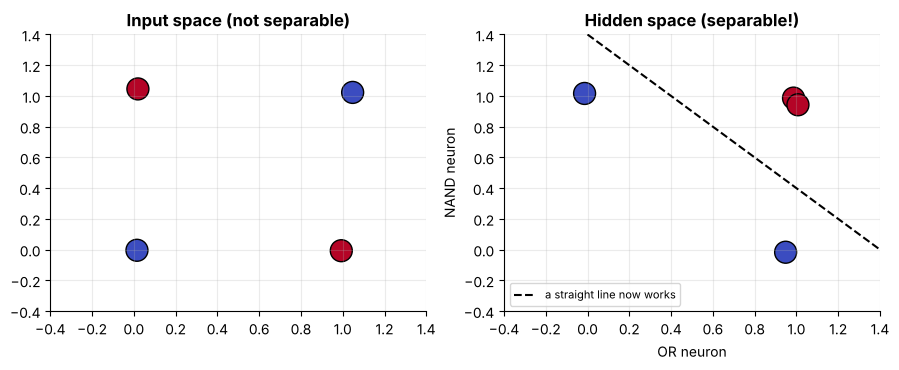

In [3]:
# Visualise: the same 4 points, before and after the hidden layer
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, P, title in [(axes[0], X, "Input space (not separable)"), (axes[1], H, "Hidden space (separable!)")]:
    jitter = 0.03 * np.random.randn(*P.shape)
    ax.scatter(P[:, 0] + jitter[:, 0], P[:, 1] + jitter[:, 1], c=[0, 1, 1, 0], cmap="coolwarm", s=250, edgecolor="k")
    ax.set_title(title); ax.set_xlim(-.4, 1.4); ax.set_ylim(-.4, 1.4)
axes[1].plot([0, 1.4], [1.4, 0], "k--", label="a straight line now works"); axes[1].legend(loc="lower left", fontsize=8)
axes[1].set_xlabel("OR neuron"); axes[1].set_ylabel("NAND neuron"); plt.tight_layout(); plt.show()

---
## 📦 2. Layers are matrices: and shapes are everything

A **layer** is just many neurons looking at the *same* inputs. If a layer has `n_in` inputs and `n_out` neurons, its
weights form a matrix **W of shape `(n_in, n_out)`**: column *j* holds neuron *j*'s weights, and its biases form a vector **b of shape `(n_out,)`**.

For a **batch** of `m` examples stacked as `X` (shape `(m, n_in)`):

$$Z = XW + b \qquad A = f(Z)$$

| Layer type | Role | Size is decided by… |
|:--|:--|:--|
| **Input layer** | Just holds the data: no weights, no computation | The data (784 for a 28×28 image) |
| **Hidden layer(s)** | Learn intermediate features | *You* (hyperparameter: "width") |
| **Output layer** | Produce the answer | The task (10 digit classes → 10 outputs; price → 1 output) |

**Shape tracing** is the skill that saves you hours of debugging. Let's trace a 784 → 128 → 64 → 10 digit classifier on a batch of 32 images:

In [4]:
batch, sizes = 32, [784, 128, 64, 10]
x = np.random.randn(batch, sizes[0])
print(f"input            : {x.shape}")
rng = np.random.default_rng(0)
for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:]), 1):
    W, b = rng.normal(0, 0.05, (n_in, n_out)), np.zeros(n_out)
    x = np.maximum(0, x @ W + b)
    print(f"layer {i}: W{W.shape} b{b.shape} → {x.shape}")

input            : (32, 784)
layer 1: W(784, 128) b(128,) → (32, 128)
layer 2: W(128, 64) b(64,) → (32, 64)
layer 3: W(64, 10) b(10,) → (32, 10)


> 🛠 **Pro tip**: Rule of thumb: in `X @ W`, **the inner dimensions must match**: `(m, n_in) @ (n_in, n_out) → (m, n_out)`. PyTorch's `nn.Linear(in_features, out_features)` stores W transposed (`(out, in)`) and computes `x @ W.T + b`: same maths, different bookkeeping.

---
## 🔢 3. Counting parameters

**Parameters** are the numbers training adjusts. A dense layer `n_in → n_out` has

$$\underbrace{n_{in}\times n_{out}}_{\text{weights}} + \underbrace{n_{out}}_{\text{biases}}$$

parameters. Total for our digit net 784 → 128 → 64 → 10:

| Layer | Weights | Biases | Total |
|:--|--:|--:|--:|
| 784 → 128 | 784·128 = 100,352 | 128 | 100,480 |
| 128 → 64 | 128·64 = 8,192 | 64 | 8,256 |
| 64 → 10 | 64·10 = 640 | 10 | 650 |
| **Total** | | | **109,386** |

Let's confirm with code: a habit you should keep: *compute by hand, then verify.*

In [5]:
def n_params(sizes):
    return sum(n_in * n_out + n_out for n_in, n_out in zip(sizes[:-1], sizes[1:]))
print("784-128-64-10 →", n_params([784, 128, 64, 10]), "parameters")
print("A 'big' 4096-4096-4096-1000 network →", f"{n_params([4096, 4096, 4096, 1000]):,}", "parameters")

784-128-64-10 → 109386 parameters
A 'big' 4096-4096-4096-1000 network → 37,659,624 parameters


> 🇰🇪 **In the field**: Why care? Parameters = memory + compute + overfitting risk. A farmer's phone with 2 GB RAM can't run a 500-million-parameter model, but it can run a 500-thousand-parameter one offline. Model size is a *design constraint*, not an afterthought.

---
## 🚫 4. Why we need non-linearity

Suppose we stack two layers but forget the activation functions:
$$ (XW_1 + b_1)W_2 + b_2 = X\underbrace{(W_1W_2)}_{W'} + \underbrace{(b_1W_2 + b_2)}_{b'} $$
That's just **one** linear layer with weights $W'$! Without non-linear activations, **depth is an illusion**: 100 layers
collapse to one straight cut. Let's prove it numerically:

In [6]:
rng = np.random.default_rng(1)
X = rng.normal(size=(5, 3))
W1, b1 = rng.normal(size=(3, 4)), rng.normal(size=4)
W2, b2 = rng.normal(size=(4, 2)), rng.normal(size=2)

two_layers = (X @ W1 + b1) @ W2 + b2
W_eq, b_eq = W1 @ W2, b1 @ W2 + b2
one_layer = X @ W_eq + b_eq
print("identical?", np.allclose(two_layers, one_layer))

identical? True


> 💡 **Big idea**: The activation function is the **bend** that lets each layer do something the previous couldn't. Linear → linear → linear is a ruler. Linear → bend → linear → bend is a *sculptor's tool*.

---
## 🦓 5. The activation-function zoo

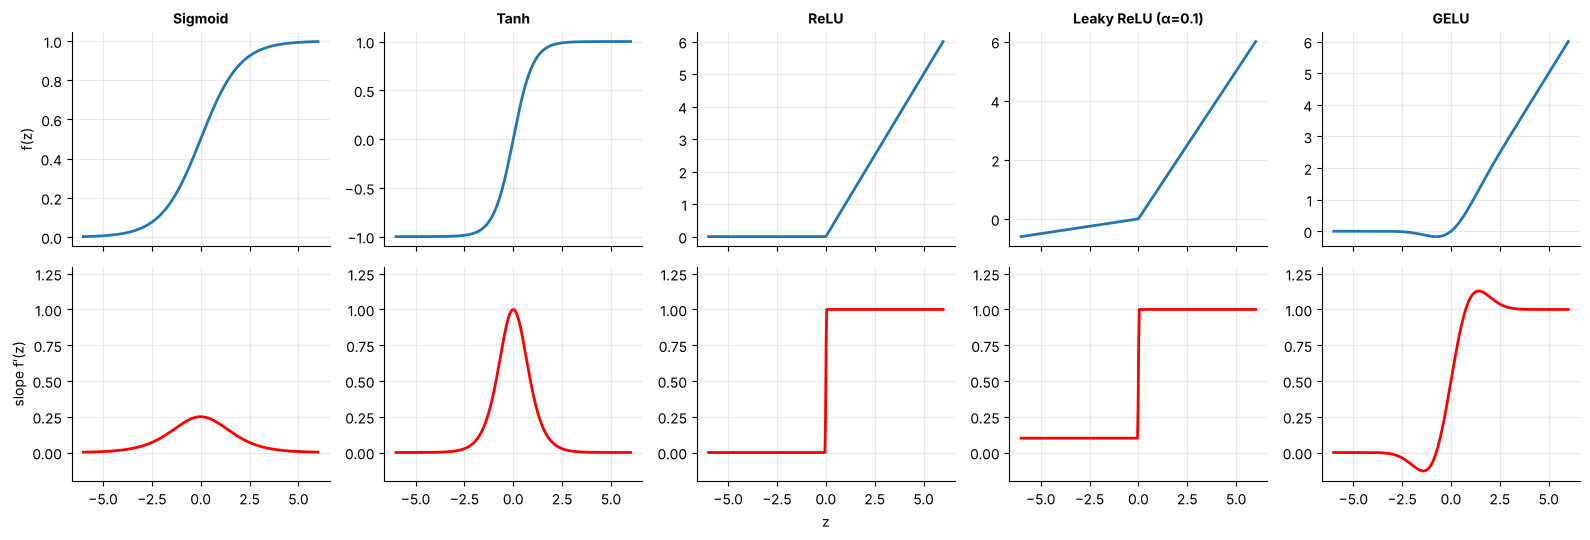

In [7]:
z = np.linspace(-6, 6, 400)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
tanh = np.tanh
relu = lambda z: np.maximum(0, z)
leaky = lambda z, a=0.1: np.where(z > 0, z, a * z)
gelu = lambda z: 0.5 * z * (1 + np.tanh(np.sqrt(2 / np.pi) * (z + 0.044715 * z ** 3)))
acts = {"Sigmoid": sigmoid, "Tanh": tanh, "ReLU": relu, "Leaky ReLU (α=0.1)": leaky, "GELU": gelu}

fig, axes = plt.subplots(2, 5, figsize=(16, 5.5), sharex=True)
for j, (name, f) in enumerate(acts.items()):
    axes[0, j].plot(z, f(z), lw=2); axes[0, j].set_title(name, fontsize=10)
    d = np.gradient(f(z), z)                              # numerical derivative
    axes[1, j].plot(z, d, "r", lw=2); axes[1, j].set_ylim(-.2, 1.3)
axes[0, 0].set_ylabel("f(z)"); axes[1, 0].set_ylabel("slope f′(z)"); axes[1, 2].set_xlabel("z")
plt.tight_layout(); plt.show()

| Activation | Formula | Range | Pros | Cons | Typical use |
|:--|:--|:-:|:--|:--|:--|
| **Step** | 1 if z>0 | {0,1} | Simple | Zero gradient everywhere → can't learn by gradient descent | Historical |
| **Sigmoid** | $1/(1+e^{-z})$ | (0,1) | Smooth, probability-like | **Saturates** (slope≈0 at the ends), not zero-centred | Binary output, LSTM gates |
| **Tanh** | $\tanh z$ | (−1,1) | Zero-centred | Also saturates | RNN/LSTM hidden state |
| **ReLU** | $\max(0,z)$ | [0,∞) | Fast, no saturation for z>0, sparse | "Dead neurons" (stuck at 0 for z<0) | **Default for hidden layers** |
| **Leaky ReLU** | $\max(\alpha z, z)$ | (−∞,∞) | Fixes dead neurons | Extra hyperparameter | When ReLU dies |
| **GELU** | $z\,\Phi(z)$ | ≈[−0.17,∞) | Smooth ReLU | Slightly costlier | **Transformers** |
| **Softmax** | $e^{z_i}/\sum_j e^{z_j}$ | (0,1), sums to 1 | Turns scores into probabilities | - | **Multi-class output** |

**Which should I use?** → Hidden layers: start with **ReLU**. Binary classification output: **sigmoid**.
Multi-class output: **softmax**. Regression output: **none** (linear). Transformers: **GELU**. Don't agonise; ReLU rarely loses badly.

🤔 **Pause and think.** Look at the bottom row (slopes). Sigmoid's slope never exceeds what value? What do you think happens to learning when a neuron's z is +6 or −6?

<details><summary>Click to reveal the answer</summary>

Sigmoid's maximum slope is **0.25** (at z=0), and it's nearly **0** at ±6. A neuron in that saturated zone barely responds to weight changes, so its weights barely learn: the *vanishing gradient* problem (Section 7).

</details>

---
## 🎲 6. Softmax: scores → probabilities

For a 10-class problem the last layer produces 10 raw scores called **logits**: e.g. `[2.0, 1.0, 0.1]`. Softmax turns them into a probability distribution:

$$\text{softmax}(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$

Exponentiating makes everything positive and amplifies the biggest score; dividing by the sum makes them add to 1.

In [8]:
def softmax_naive(z):
    e = np.exp(z)
    return e / e.sum()

def softmax(z):
    e = np.exp(z - np.max(z))            # subtract max: same answer, but no overflow!
    return e / e.sum()

logits = np.array([2.0, 1.0, 0.1])
print("softmax:", softmax(logits).round(3), " sum =", softmax(logits).sum())

big = np.array([1000., 1001., 1002.])
print("naive on big logits :", softmax_naive(big), "  ← nan! exp(1000) overflows")
print("stable on big logits:", softmax(big).round(3))

softmax: [0.659 0.242 0.099]  sum = 1.0
naive on big logits : [nan nan nan]   ← nan! exp(1000) overflows
stable on big logits: [0.09  0.245 0.665]


/tmp/ipykernel_211/43908117.py:2: RuntimeWarning: overflow encountered in exp
  e = np.exp(z)
/tmp/ipykernel_211/43908117.py:3: RuntimeWarning: invalid value encountered in divide
  return e / e.sum()


> ⚠️ **Watch out**: Always subtract `max(z)` before exponentiating. Adding or subtracting a constant from all logits **doesn't change** softmax (it cancels top and bottom), but it keeps numbers in a safe range. PyTorch's `CrossEntropyLoss` does this for you.

In [9]:
# "Temperature": divide logits by T before softmax. T<1 sharpens, T>1 flattens
for T in [0.5, 1.0, 3.0]:
    print(f"T={T}:", softmax(logits / T).round(3))

T=0.5: [0.864 0.117 0.019]
T=1.0: [0.659 0.242 0.099]
T=3.0: [0.445 0.319 0.236]


---
## 📉 7. Vanishing gradients & why initialisation matters

Learning (Lesson 04) multiplies slopes layer after layer. If each slope is < 1, the product **shrinks exponentially** with depth.
With sigmoid, the biggest possible slope is 0.25:

In [10]:
for depth in [2, 5, 10, 20]:
    print(f"{depth:2d} sigmoid layers → gradient shrinks by at least a factor of {0.25 ** depth:.1e}")

 2 sigmoid layers → gradient shrinks by at least a factor of 6.2e-02
 5 sigmoid layers → gradient shrinks by at least a factor of 9.8e-04
10 sigmoid layers → gradient shrinks by at least a factor of 9.5e-07
20 sigmoid layers → gradient shrinks by at least a factor of 9.1e-13


Early layers would receive essentially **no learning signal**. This is why ReLU (slope exactly 1 for z>0) revolutionised deep learning.

**Initialisation** matters for the same reason. If starting weights are too small, signals shrink layer by layer to zero;
too large, they explode. And if all weights start *equal* (e.g., zero), every neuron in a layer computes the same thing and gets
the same update: they never differentiate (the **symmetry problem**). Let's watch a signal travel through 10 ReLU layers of width 256 under three initialisations:

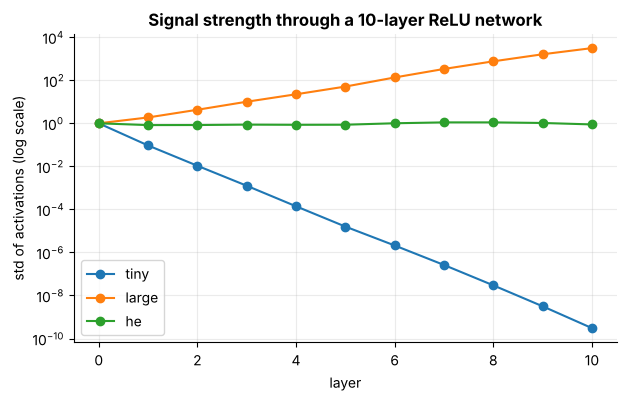

In [11]:
def signal_through_layers(init, depth=10, width=256, n=512):
    rng = np.random.default_rng(0)
    a = rng.normal(size=(n, width))
    stds = [a.std()]
    for _ in range(depth):
        if init == "tiny":      W = rng.normal(0, 0.01, (width, width))
        elif init == "large":   W = rng.normal(0, 0.2, (width, width))
        elif init == "he":      W = rng.normal(0, np.sqrt(2 / width), (width, width))   # He/Kaiming init for ReLU
        a = np.maximum(0, a @ W)
        stds.append(a.std())
    return stds

for init in ["tiny", "large", "he"]:
    plt.semilogy(signal_through_layers(init), "o-", label=init)
plt.xlabel("layer"); plt.ylabel("std of activations (log scale)"); plt.legend(); plt.title("Signal strength through a 10-layer ReLU network")
plt.show()

* **tiny** → signal vanishes. **large** → signal explodes. **He init** ($\sigma=\sqrt{2/n_{in}}$) keeps the signal steady.
* Rules: **ReLU → He (Kaiming)** init; **tanh/sigmoid → Xavier/Glorot** init ($\sigma=\sqrt{2/(n_{in}+n_{out})}$). PyTorch's `nn.Linear` defaults are sensible, so you rarely set this by hand, but now you know *why* it matters.

---
## 🔭 8. Universal approximation: seeing is believing

A famous theorem says a network with **one hidden layer** and enough neurons can approximate (almost) any smooth function.
We can *see* why: each ReLU neuron is a "hinge"; adding enough hinges at different positions builds any curve out of straight segments.

Experiment: give the hidden layer **random** weights, and *only fit the output weights* (a simple least-squares problem). More hidden neurons → better fit of $\sin(x)$.

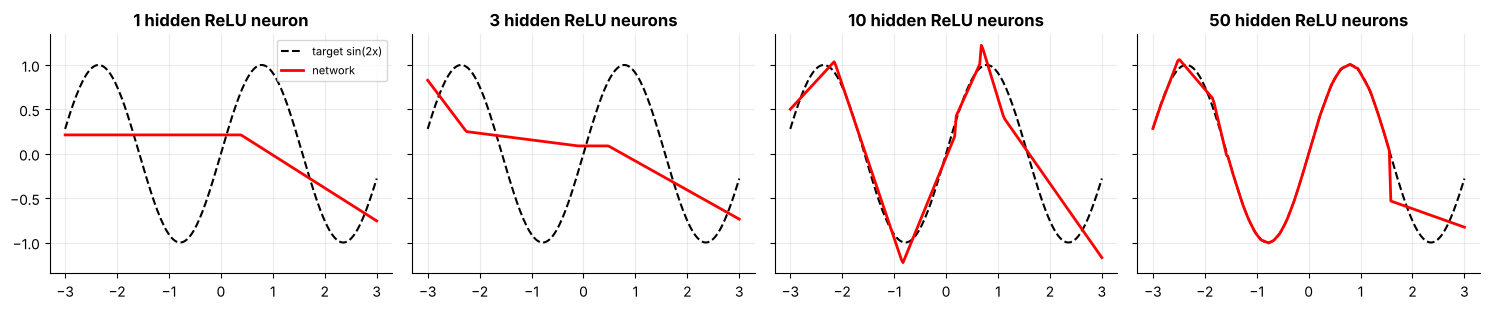

In [12]:
rng = np.random.default_rng(3)
x = np.linspace(-3, 3, 200).reshape(-1, 1); y = np.sin(2 * x)
fig, axes = plt.subplots(1, 4, figsize=(15, 3.2), sharey=True)
for ax, h in zip(axes, [1, 3, 10, 50]):
    W1, b1 = rng.normal(size=(1, h)) * 2, rng.uniform(-3, 3, h)
    H = np.maximum(0, x @ W1 + b1)                          # hidden ReLU features
    H1 = np.c_[H, np.ones(len(x))]
    w2, *_ = np.linalg.lstsq(H1, y, rcond=None)             # fit the output layer only
    ax.plot(x, y, "k--", label="target sin(2x)"); ax.plot(x, H1 @ w2, "r", lw=2, label="network")
    ax.set_title(f"{h} hidden ReLU neuron{'s' if h > 1 else ''}")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

> 📝 **Note**: The theorem says a good network **exists**: not that gradient descent will **find** it, nor how many neurons you'd need. In practice, *deeper* networks reach the same accuracy with far fewer neurons, which is why we go *deep*.

---
# 🏋️ Practice problems
Work through these in order. Each problem has **hints** (open them one at a time: struggling a little is how learning happens!) and a **self-check cell** that tells you ✅ or ❌. Full solutions live in `../solutions/`.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 2.1: Count the parameters  &nbsp; `⭐`

Write `count_params(sizes)` for a fully connected network whose layer sizes are in the list `sizes` (e.g. `[784, 128, 64, 10]`). Include biases.

<details><summary>💡 Hint 1</summary>

For each consecutive pair `(n_in, n_out)` the layer has `n_in*n_out + n_out` parameters.

</details>

<details><summary>💡 Hint 2</summary>

`zip(sizes[:-1], sizes[1:])` gives consecutive pairs.

</details>


In [ ]:
def count_params(sizes):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
dl.check("784-128-64-10 has 109,386 params", count_params([784,128,64,10]) == 109386)
dl.check("2-2-1 XOR net has 9 params", count_params([2,2,1]) == 9)
dl.check("single layer 5→3 has 18", count_params([5,3]) == 18)

---
### 🧩 Problem 2.2: Stable softmax  &nbsp; `⭐⭐`

Implement `softmax(z)` that works on a **batch**: `z` has shape `(m, k)`; each *row* must become a probability distribution. It must not overflow for logits like `1000`.

<details><summary>💡 Hint 1</summary>

Subtract the **row-wise** max with `keepdims=True` so broadcasting works.

</details>

<details><summary>💡 Hint 2</summary>

`z.max(axis=1, keepdims=True)` and `e.sum(axis=1, keepdims=True)`.

</details>


In [ ]:
def softmax(z):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
z = np.array([[2., 1., .1], [1000., 1001., 1002.]])
p = softmax(z)
dl.check("no NaN / inf", p is not None and np.isfinite(p).all())
dl.check("each row sums to 1", p is not None and np.allclose(p.sum(1), 1))
dl.check("first row correct", p is not None and np.allclose(p[0], [0.659, 0.242, 0.099], atol=1e-3))
dl.check("shift invariance", p is not None and np.allclose(softmax(z + 5), p))

---
### 🧩 Problem 2.3: Forward pass of a whole network  &nbsp; `⭐⭐`

Write `forward(X, params)` where `params` is a list of `(W, b)` tuples. Apply **ReLU after every layer except the last**
(the last layer stays linear; those are the logits). Return the logits.

<details><summary>💡 Hint 1</summary>

Loop over layers; keep a running `A = X`.

</details>

<details><summary>💡 Hint 2</summary>

`A = A @ W + b`, then apply ReLU only if it's not the last layer: `enumerate(params)` gives you the index.

</details>


In [ ]:
def forward(X, params):
    pass   # YOUR CODE HERE

In [ ]:
# ▶ self-check (run after you've written your answer)
rng = np.random.default_rng(0)
params = [(rng.normal(size=(4, 6)), rng.normal(size=6)), (rng.normal(size=(6, 3)), rng.normal(size=3))]
X = rng.normal(size=(7, 4))
out = forward(X, params)
expected = np.maximum(0, X @ params[0][0] + params[0][1]) @ params[1][0] + params[1][1]
dl.check("output shape (7, 3)", out is not None and out.shape == (7, 3))
dl.check("matches manual computation", out is not None and np.allclose(out, expected))

---
### 🧩 Problem 2.4: Hand-build XOR with ReLU  &nbsp; `⭐⭐⭐`

Find weights for a **2 → 2 → 1 network with ReLU hidden units and a linear output** that computes XOR exactly on the four binary inputs
(outputs 0, 1, 1, 0). Fill `W1 (2×2)`, `b1 (2,)`, `W2 (2×1)`, `b2 (1,)`.

<details><summary>💡 Hint 1</summary>

Think of two hinge functions. One hidden unit can compute `x1 + x2`. What should the other compute so their *difference* creates the dip at (1,1)?

</details>

<details><summary>💡 Hint 2</summary>

Try hidden unit 1 = ReLU(x1 + x2), hidden unit 2 = ReLU(x1 + x2 − 1).

</details>

<details><summary>💡 Hint 3</summary>

Output = h1 − 2·h2. Check: (1,1) → 2 − 2·1 = 0 ✔️, (0,1) → 1 − 0 = 1 ✔️

</details>


In [ ]:
W1 = None; b1 = None; W2 = None; b2 = None   # numpy arrays of the right shapes

In [ ]:
# ▶ self-check (run after you've written your answer)
X = np.array([[0,0],[0,1],[1,0],[1,1]], float)
try:
    out = (np.maximum(0, X @ W1 + b1) @ W2 + b2).ravel()
    dl.check("XOR outputs are [0,1,1,0]", np.allclose(out, [0, 1, 1, 0]))
except Exception as e:
    dl.check("XOR outputs are [0,1,1,0]", False, f"({type(e).__name__}) fill in all four arrays")

---
### 🧩 Problem 2.5: Activation derivatives  &nbsp; `⭐⭐`

Implement the **derivative** functions `d_sigmoid(z)`, `d_tanh(z)`, `d_relu(z)` (we'll need them for backpropagation).
Facts: $\sigma'(z)=\sigma(z)(1-\sigma(z))$, $\tanh'(z)=1-\tanh^2(z)$, ReLU′ = 1 if z>0 else 0.
Verify numerically in the self-check.

<details><summary>💡 Hint 1</summary>

Compute `s = 1/(1+np.exp(-z))` first, then `s*(1-s)`.

</details>

<details><summary>💡 Hint 2</summary>

`(z > 0).astype(float)` for ReLU.

</details>


In [ ]:
def d_sigmoid(z):
    pass
def d_tanh(z):
    pass
def d_relu(z):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
z = np.linspace(-3, 3, 13) + 0.013; h = 1e-6
sig = lambda z: 1/(1+np.exp(-z))
num = lambda f: (f(z + h) - f(z - h)) / (2 * h)
try:
    dl.check("sigmoid′ matches numerical", np.allclose(d_sigmoid(z), num(sig), atol=1e-5))
    dl.check("tanh′ matches numerical", np.allclose(d_tanh(z), num(np.tanh), atol=1e-5))
    dl.check("ReLU′ matches numerical", np.allclose(d_relu(z), num(lambda t: np.maximum(0, t)), atol=1e-5))
    dl.check("max of sigmoid′ is 0.25", np.isclose(d_sigmoid(np.array([0.0]))[0], 0.25))
except Exception:
    dl.check("implement all three functions", False)

---
## 🏁 Key takeaways
- ✅ A **layer** = a matrix multiply plus bias (`XW + b`), then an activation. Hidden layers learn *representations*.
- ✅ **Shape discipline**: `(m, n_in) @ (n_in, n_out) → (m, n_out)`. Parameters per layer = `n_in·n_out + n_out`.
- ✅ Without **non-linear** activations, any depth collapses to one linear map.
- ✅ Defaults: **ReLU** hidden · **sigmoid** binary output · **softmax** multiclass output · **linear** regression output.
- ✅ **Sigmoid/tanh saturate → vanishing gradients**; ReLU + **He initialisation** keep signals healthy.
- ✅ One hidden layer can approximate any function in theory; **depth** makes it efficient in practice.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** A network has layers 10 → 20 → 5. How many weights and biases?

<details><summary>Answer</summary>

Weights: 10·20 + 20·5 = 300. Biases: 20 + 5 = 25. Total **325**.

</details>

**Q2.** Why can't we use the step function as an activation in a trained network?

<details><summary>Answer</summary>

Its derivative is 0 everywhere (and undefined at 0), so gradient descent receives no signal about which way to change the weights.

</details>

**Q3.** You see `nan` in your softmax output for large logits. What's the fix?

<details><summary>Answer</summary>

Subtract the max logit before exponentiating (the *log-sum-exp trick*).

</details>

**Q4.** Why is initialising all weights to zero a bad idea?

<details><summary>Answer</summary>

Every neuron in a layer would compute the same output and receive identical gradient updates, so they'd stay identical forever: the layer behaves like a single neuron.

</details>

---
## 📚 Go deeper (optional)
- Glorot & Bengio (2010): *Understanding the difficulty of training deep feedforward neural networks*
- He et al. (2015): *Delving Deep into Rectifiers* (He initialisation)
- Cybenko (1989) / Hornik (1991); Universal approximation theorems
- Distill.pub: *Deep Learning Visualised* playgrounds; also try playground.tensorflow.org to see hidden layers re-draw data live

---
⬅️ Previous: [01 · The Artificial Neuron & the Perceptron](01_neuron_and_perceptron.ipynb) &nbsp;|&nbsp; Next: [03 · Forward Propagation & Loss Functions](03_forward_prop_and_loss.ipynb) ➡️